# Exporter de la volaille bio : préparation des données

**Notebook 1 sur 2 : préparer, nettoyer et explorer les données.**

Un producteur français de poulets bio veut savoir dans quels pays exporter, sans écarter aucun pays au départ.
Avant de comparer les pays, il faut un tableau propre : un pays par ligne, une information par
colonne, et aucune case vide. C'est ce que je construis ici. Le notebook 2 s'en servira pour
regrouper les pays qui se ressemblent.

Pour que l'étude soit solide, je me fixe quatre règles : au moins 8 informations par pays, dont au
moins 3 que je calcule moi-même ; au moins 100 pays ; des pays qui réunissent au moins 60 % de la
population mondiale ; et aucune case vide.

## Les données utilisées

Les fichiers de départ décrivaient l'année 2017. Pour décider aujourd'hui dans quels pays exporter,
c'est trop ancien : depuis, le Covid, la guerre en Ukraine et la sortie du Royaume-Uni de l'Union
européenne ont pu changer les échanges de volaille. J'ai donc choisi de travailler sur **2023, la
dernière année publiée par la FAO**.

Ce sont les mêmes bilans alimentaires, avec les mêmes définitions et les mêmes codes : seuls l'année
et les chiffres changent. Les indicateurs de la Banque mondiale (richesse, urbanisation, stabilité
politique, densité) sont pris pour la même année, pour que tout le tableau décrive le même moment.

## Le plan
1. les réglages ;
2. les deux fichiers de la FAO ;
3. la volaille, pays par pays ;
4. la part de la volaille dans la viande (variable créée n°1) ;
5. la population et sa croissance (variable créée n°2) ;
6. les données de la Banque mondiale (grille PESTEL) ;
7. tout réunir dans un seul tableau ;
8. les cases vides ;
9. la dépendance aux importations (variable créée n°3) ;
10. la distance avec la France (variable créée n°4) ;
11. les variables gardées ;
12. les valeurs extrêmes ;
13. les liens entre les variables ;
14. enregistrer le tableau pour le notebook 2.

## 1. Les réglages

In [1]:
import numpy as np                # les calculs (la distance, le logarithme)
import pandas as pd               # les tableaux
import matplotlib.pyplot as plt   # les graphiques
import seaborn as sns             # des graphiques plus jolis

DOSSIER = "../data/"   # les fichiers CSV sont dans le dossier data du projet

## 2. Les deux fichiers de la FAO

Je pars de deux fichiers de la FAO, l'organisation des Nations unies pour l'alimentation. Le
premier, le bilan alimentaire 2023, dit pour chaque pays et chaque produit combien est produit,
importé, exporté et mangé. Le second donne la population de chaque pays, de 2000 à 2023.

In [2]:
dispo = pd.read_csv(DOSSIER + "DisponibiliteAlimentaire_2023.csv")
population = pd.read_csv(DOSSIER + "Population_2000_2023.csv")

print("bilan alimentaire :", dispo.shape)   # (nombre de lignes, nombre de colonnes)
print("population :", population.shape)
dispo.head(3)

bilan alimentaire : (177323, 14)
population : (5530, 15)


,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole
0,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,645,Disponibilité alimentaire en quantité (kg/pers...,2511,Blé et produits,2023,2023,kg,163.32,E,Valeur estimée
1,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,664,Disponibilité alimentaire (Kcal/personne/jour),2511,Blé et produits,2023,2023,Kcal/personne/jour,1369.98,E,Valeur estimée
2,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,674,Disponibilité de protéines en quantité (g/pers...,2511,Blé et produits,2023,2023,g/personne/jour,41.35,E,Valeur estimée


Le bilan est rangé « en long » : il y a une ligne pour chaque combinaison pays, produit et mesure
(production, importations…). L'Allemagne apparaît donc sur des centaines de lignes. Pour comparer les
pays, il me faudra une seule ligne par pays : je le remettrai à plat à l'étape 3.

In [3]:
# qu'est-ce qui est mesuré, et dans quelle unité ?
dispo.groupby(["Élément", "Unité"]).size()

Élément                                                        Unité             
Alimentation pour touristes                                    Milliers de tonnes     2417
Aliments pour animaux                                          Milliers de tonnes     4971
Autres utilisations (non alimentaire)                          Milliers de tonnes     3323
Disponibilité alimentaire (Kcal/personne/jour)                 Kcal/personne/jour    14835
Disponibilité alimentaire en quantité (kg/personne/an)         kg                    15063
Disponibilité de matière grasse en quantité (g/personne/jour)  g/personne/jour       14835
Disponibilité de protéines en quantité (g/personne/jour)       g/personne/jour       14835
Disponibilité intérieure                                       Milliers de tonnes    16244
Exportations - Quantité                                        Milliers de tonnes    11949
Importations - Quantité                                        Milliers de tonnes    15529
Nourritu

In [4]:
# et la population, dans quelle unité ?
population["Unité"].unique()

array(['1000 personnes'], dtype=object)

Les quantités (production, importations…) sont en milliers de tonnes, et la quantité disponible par
personne, celle que je garde, est en kilos par an. La population est en milliers de personnes : je la diviserai par
1 000 pour parler en millions, c'est plus parlant. Pour ne jamais mélanger les unités, je les écris
dans le nom des colonnes (`_kt` pour milliers de tonnes, `_kg_hab` pour kilos par habitant).

## 3. La volaille, pays par pays

La volaille, c'est notre produit, donc c'est là que je regarde d'abord. Pour chaque pays, je garde
4 informations :
- la **production** : ce que le pays produit lui-même ;
- les **importations** : ce qu'il achète déjà à l'étranger. C'est la place que nous pourrions prendre ;
- la **disponibilité intérieure** : toute la volaille dont le pays dispose. Elle me servira à calculer
  la dépendance aux importations (étape 9) ;
- les **kilos par habitant** : ce que chaque habitant mange par an.

In [5]:
volaille = dispo[dispo["Produit"] == "Viande de Volailles"]   # on ne garde que la volaille

noms = {                                  # nom de l'élément FAO -> nom de ma colonne
    "Production": "production_volaille_kt",
    "Importations - Quantité": "importations_volaille_kt",
    "Disponibilité intérieure": "dispo_interieure_volaille_kt",
    "Disponibilité alimentaire en quantité (kg/personne/an)": "volaille_kg_hab",
}
volaille = volaille[volaille["Élément"].isin(noms)]          # on ne garde que ces 4 éléments
volaille = volaille.pivot_table(index="Zone", columns="Élément", values="Valeur")   # long -> large
volaille = volaille.rename(columns=noms)

print(len(volaille), "pays")
volaille.head()

176 pays


Élément,volaille_kg_hab,dispo_interieure_volaille_kt,importations_volaille_kt,production_volaille_kt
Zone,,,,
Afghanistan,0.81,34.0,5.0,29.0
Afrique du Sud,33.95,2146.0,329.0,1867.0
Albanie,24.78,70.0,52.0,18.0
Algérie,9.88,456.0,0.0,458.0
Allemagne,16.77,1508.0,777.0,1531.0


In [6]:
# combien de cases vides dans chaque colonne ?
volaille.isna().sum()

Élément
volaille_kg_hab                 0
dispo_interieure_volaille_kt    0
importations_volaille_kt        0
production_volaille_kt          3
dtype: int64

Quelques cases sont vides. En général, quand la FAO n'écrit pas de ligne, c'est que la quantité est
nulle : un pays qui ne produit pas de volaille n'a tout simplement pas de ligne « Production ». Je
n'y touche pas encore. La Banque mondiale va apporter ses propres trous, et je préfère traiter toutes
les cases vides d'un coup, avec une seule règle, à l'étape 8.

## 4. La part de la volaille dans la viande (variable créée n°1)

Savoir qu'un habitant mange 20 kg de volaille par an ne suffit pas. Dans un pays où l'on mange
surtout du bœuf, 20 kg, c'est peu ; dans un pays qui mange peu de viande, c'est beaucoup. Ce qui
m'intéresse, c'est la place de la volaille dans l'assiette : si c'est déjà la viande principale, nos
clients la connaissent. Je calcule donc **la part de la volaille dans la viande mangée**, en %.

In [7]:
viandes = ["Viande de Volailles", "Viande de Bovins", "Viande de Suides",
           "Viande d'Ovins/Caprins", "Viande, Autre"]          # "Suides" = le porc

lignes = dispo[dispo["Produit"].isin(viandes)
               & (dispo["Élément"] == "Disponibilité alimentaire en quantité (kg/personne/an)")]
viande_kg_hab = lignes.groupby("Zone")["Valeur"].sum()       # kilos de viande par habitant, par pays

volaille["part_volaille_viande_pct"] = volaille["volaille_kg_hab"] / viande_kg_hab * 100
volaille["part_volaille_viande_pct"].describe()               # vérifier : tout entre 0 et 100 ?

count    176.000000
mean      44.480387
std       19.529637
min        5.619216
25%       30.147590
50%       42.914958
75%       58.831075
max       88.321799
Name: part_volaille_viande_pct, dtype: float64

Toutes les valeurs sont bien entre 0 et 100 %, le calcul est juste. Je n'ai compté ni le poisson
ni les abats, car ma question est simple : « quand on mange de la viande, est-ce de la volaille ? ».

## 5. La population et sa croissance (variable créée n°2)

Un pays dont la population augmente, c'est un marché qui grandit tout seul, sans effort de notre
part. Je garde donc la population de 2023 et je calcule **la croissance de la population sur 10 ans**
(de 2013 à 2023), en %.

In [8]:
# un pays par ligne, une année par colonne
pop = population.pivot_table(index="Zone", columns="Année", values="Valeur")

demographie = pd.DataFrame()
demographie["population_millions"] = pop[2023] / 1000
demographie["croissance_pop_10ans_pct"] = (pop[2023] / pop[2013] - 1) * 100  # taux d'évolution

POPULATION_MONDE = pop[2023].sum() / 1000
print("population mondiale 2023 :", round(POPULATION_MONDE), "millions")
demographie.sort_values("population_millions", ascending=False).head()

population mondiale 2023 : 8089 millions


,population_millions,croissance_pop_10ans_pct
Zone,,
Inde,1438.069596,10.976759
"Chine, continentale",1422.584933,3.160017
États-Unis d'Amérique,343.477335,7.299528
Indonésie,281.190067,9.903207
Pakistan,247.504495,17.259597


Je garde la population mondiale de côté pour vérifier à l'étape 8 que les pays de l'étude réunissent au moins 60 % de la population globale.

Concernant la Chine, je laisse ses quatre zones séparées (continentale, Hong Kong, Macao, Taïwan) : ce sont quatre marchés d'exportation distincts avec leurs propres règles.

## 6. Les données de la Banque mondiale (grille PESTEL)

Pour choisir nos marchés d'exportation, la FAO ne suffit pas : elle donne les volumes de volaille, mais rien sur l'argent ou les risques.

La grille PESTEL propose six angles pour analyser un pays (politique, économique, social, technologique, environnemental, légal). Je garde les trois qui ont un chiffre pour tous les pays, et pour chacun les questions qui comptent pour vendre du poulet bio :

| Angle | Ma question | Variable | Source |
|---|---|---|---|
| Politique | Peut-on y vendre sans risque ? | stabilité politique (de -2,5 à +2,5) | Banque mondiale |
| Économique | Les habitants peuvent-ils payer du bio, plus cher ? | PIB par habitant en parité de pouvoir d'achat | Banque mondiale |
| Économique | Est-ce loin ? (un poulet frais voyage mal) | distance avec la France | calculée à l'étape 10 |
| Social | Les habitants vivent-ils en ville, près des magasins ? | part de la population en ville | Banque mondiale |
| Social | Les clients sont-ils concentrés ? | densité de population (habitants au km²) | Banque mondiale |
| Social | Le marché grandit-il ? | croissance de la population | FAO (étape 5) |

Les chiffres de la Banque mondiale sont téléchargés en CSV sur son site. Je prends l'année 2023, comme pour la FAO, pour que tout le tableau parle du même moment.

Les trois autres angles (technologique, environnemental, légal) n'ont pas de chiffre disponible pour tous les pays. Le légal et le sanitaire (douane, règles d'import) sont dans les limites, à la fin du notebook 2.

In [9]:
# PIB par habitant et urbanisation : fichiers téléchargés sur donnees.banquemondiale.org
# les 4 premières lignes du fichier sont des informations, pas des données : on les saute
pib = pd.read_csv(DOSSIER + "bm_pib.csv", skiprows=4)
urbanisation = pd.read_csv(DOSSIER + "bm_urbanisation.csv", skiprows=4)

# stabilité politique : dans le fichier des indicateurs de gouvernance (base « WGI » de la Banque mondiale)
gouvernance = pd.read_csv(DOSSIER + "bm_gouvernance.csv")       # ici, pas de lignes à sauter
stabilite = gouvernance[gouvernance["Indicator Code"] == "GOV_WGI_PV.EST"]   # la ligne « stabilité politique »

# densité de population (habitants au km²) : même format que le PIB, 4 lignes à sauter
densite = pd.read_csv(DOSSIER + "bm_densite.csv", skiprows=4)

# la capitale de chaque pays, avec sa latitude et sa longitude (pour la distance, étape 10)
capitales = pd.read_csv(DOSSIER + "bm_capitales.csv")

pib.head(3)

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"PIB par habitant, ($ PPA internationaux consta...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,38213.289239,39378.228411,39754.560072,30408.827090,35207.170909,39083.461640,42783.248907,45428.002728,NaN,NaN
1,NaN,AFE,"PIB par habitant, ($ PPA internationaux consta...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,4223.188050,4229.839634,4200.531044,3978.133502,4049.969513,4098.126192,4076.224898,4099.889812,4164.679177,NaN
2,Afghanistan,AFG,"PIB par habitant, ($ PPA internationaux consta...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN,NaN


In [10]:
# je garde le code pays et l'année 2023, et je donne un nom clair à chaque colonne
pib          = pib[["Country Code", "2023"]].rename(columns={"2023": "pib_hab_ppa"})
urbanisation = urbanisation[["Country Code", "2023"]].rename(columns={"2023": "urbanisation_pct"})
stabilite    = stabilite[["Country Code", "2023"]].rename(columns={"2023": "stabilite_politique"})
densite      = densite[["Country Code", "2023"]].rename(columns={"2023": "densite_hab_km2"})
capitales    = capitales[["Country Code", "latitude", "longitude"]]

# 4 pays n'ont pas de coordonnées dans le fichier des capitales : je les ajoute à la main
ajouts = pd.DataFrame({
    "Country Code": ["HKG", "MAC", "ISR", "TUV"],   # Hong Kong, Macao, Israël, Tuvalu
    "latitude":     [22.3193, 22.1987, 32.0853, -8.5211],
    "longitude":    [114.1694, 113.5439, 34.7818, 179.1983],
})
capitales = pd.concat([capitales, ajouts])

# je rassemble tout dans un seul tableau, une ligne par pays
banque_mondiale = pib.merge(urbanisation, on="Country Code")
banque_mondiale = banque_mondiale.merge(stabilite, on="Country Code", how="left")
banque_mondiale = banque_mondiale.merge(densite, on="Country Code", how="left")
banque_mondiale = banque_mondiale.merge(capitales, on="Country Code", how="left")
banque_mondiale.head()

,Country Code,pib_hab_ppa,urbanisation_pct,stabilite_politique,densite_hab_km2,latitude,longitude
0,ABW,42783.248907,61.835149,1.345952,596.438889,12.51670,-70.0167
1,AFE,4076.224898,37.772301,NaN,50.514698,NaN,NaN
2,AFG,1983.812620,25.473053,-2.400719,63.558501,34.52280,69.1761
3,AFW,5886.796636,52.302109,NaN,56.193993,NaN,NaN
4,AGO,8597.538788,69.851503,-0.355809,29.477746,-8.81155,13.2420


### Relier la FAO et la Banque mondiale

La FAO utilise des noms en français et la Banque mondiale des codes à 3 lettres. Le fichier du PIB sert de dictionnaire pour faire le lien entre les deux, et la liste des pays de la Banque mondiale (`bm_pays.csv`) me permet d'écarter les regroupements (comme « Monde » ou « Zone euro »).

In [11]:
pays_bm = pd.read_csv(DOSSIER + "bm_pays.csv")
vrais_pays = pays_bm[pays_bm["Income_Group"] != "Agrégats"]["Country Code"]   # sans les regroupements

liste = pd.read_csv(DOSSIER + "bm_pib.csv", skiprows=4)
liste = liste[liste["Country Code"].isin(vrais_pays)]
nom_vers_code = dict(zip(liste["Country Name"], liste["Country Code"]))   # "France" -> "FRA"

volaille["code"] = volaille.index.map(nom_vers_code)
print("pays FAO sans code :", list(volaille[volaille["code"].isna()].index))

pays FAO sans code : ['Bolivie (État plurinational de)', 'Chine - RAS de Hong-Kong', 'Chine - RAS de Macao', 'Chine, Taiwan Province de', 'Chine, continentale', 'Congo', "Iran (République islamique d')", 'Kirghizistan', 'Micronésie (États fédérés de)', 'Nauru', "Royaume-Uni de Grande-Bretagne et d'Irlande du Nord", 'République de Corée', 'République de Moldova', 'République démocratique du Congo', 'République-Unie de Tanzanie', 'Slovaquie', 'Tchéquie', 'Venezuela (République bolivarienne du)', 'Yémen', 'Égypte', "États-Unis d'Amérique"]


Une vingtaine de noms ne s'écrivent pas pareil d'une source à l'autre (« États-Unis d'Amérique »
d'un côté, « États-Unis » de l'autre). Pour ceux-là, je donne le code à la main.

In [12]:
corrections = {
    "Bolivie (État plurinational de)": "BOL", "Chine - RAS de Hong-Kong": "HKG",
    "Chine - RAS de Macao": "MAC", "Chine, continentale": "CHN", "Congo": "COG",
    "Iran (République islamique d')": "IRN", "Kirghizistan": "KGZ",
    "Royaume-Uni de Grande-Bretagne et d'Irlande du Nord": "GBR", "République de Corée": "KOR",
    "République de Moldova": "MDA", "République populaire démocratique de Corée": "PRK",
    "République-Unie de Tanzanie": "TZA", "Slovaquie": "SVK", "Tchéquie": "CZE",
    "Venezuela (République bolivarienne du)": "VEN", "Yémen": "YEM", "Égypte": "EGY",
    "États-Unis d'Amérique": "USA", "République démocratique du Congo": "COD",
    "Micronésie (États fédérés de)": "FSM", "Nauru": "NRU",
}
nom_vers_code.update(corrections)                  # j'ajoute mes corrections au dictionnaire
volaille["code"] = volaille.index.map(nom_vers_code)
print("pays FAO sans code :", list(volaille[volaille["code"].isna()].index))

pays FAO sans code : ['Chine, Taiwan Province de']


Il ne reste que Taïwan sans code : la Banque mondiale ne publie pas de chiffres sur elle. Sans PIB,
elle sortira du tableau à l'étape 8.

## 7. Tout réunir dans un seul tableau

In [13]:
pays = volaille.join(demographie)                                  # par le nom du pays
pays = pays.merge(banque_mondiale, left_on="code", right_on="Country Code", how="left")
pays.index = volaille.index                                        # je remets le nom du pays en index
pays = pays.drop(columns=["code", "Country Code"])

print(pays.shape)
pays.head()

(176, 13)


,volaille_kg_hab,dispo_interieure_volaille_kt,importations_volaille_kt,production_volaille_kt,part_volaille_viande_pct,population_millions,croissance_pop_10ans_pct,pib_hab_ppa,urbanisation_pct,stabilite_politique,densite_hab_km2,latitude,longitude
Zone,,,,,,,,,,,,,
Afghanistan,0.81,34.0,5.0,29.0,12.676056,41.454761,31.091766,1983.812620,25.473053,-2.400719,63.558501,34.5228,69.17610
Afrique du Sud,33.95,2146.0,329.0,1867.0,58.263257,63.212384,15.606770,13695.375569,63.582371,-0.630796,52.108569,-25.7460,28.18710
Albanie,24.78,70.0,52.0,18.0,43.719125,2.811655,-3.298903,20501.647073,58.210609,0.021664,88.016715,41.3317,19.81720
Algérie,9.88,456.0,0.0,458.0,44.384546,46.164219,20.174971,15159.324237,74.732808,-0.758774,19.382560,36.7397,3.05097
Allemagne,16.77,1508.0,777.0,1531.0,23.730013,84.548231,4.326975,63140.194910,81.903437,0.534345,238.351810,52.5235,13.41150


176 pays et 13 colonnes : la FAO et la Banque mondiale sont réunies dans un seul tableau. Il reste à traiter les cases vides.

## 8. Les cases vides

Une case vide empêche de comparer les pays, donc il n'en faut aucune. Je les traite avec une règle
simple :
- **une quantité de volaille vide** (production, importations) : on a vu que la FAO n'écrit pas de
  ligne quand la quantité est nulle, donc je mets **0** ;
- **un autre chiffre vide** (PIB, stabilité, disponibilité…) : là, je ne sais vraiment pas. Inventer
  un chiffre fausserait les groupes de pays, donc **je retire le pays**.

In [14]:
colonnes_quantites = ["production_volaille_kt", "importations_volaille_kt"]
pays[colonnes_quantites] = pays[colonnes_quantites].fillna(0)     # quantité absente = 0

pays[pays.isna().any(axis=1)]     # les pays qui ont encore au moins une case vide

,volaille_kg_hab,dispo_interieure_volaille_kt,importations_volaille_kt,production_volaille_kt,part_volaille_viande_pct,population_millions,croissance_pop_10ans_pct,pib_hab_ppa,urbanisation_pct,stabilite_politique,densite_hab_km2,latitude,longitude
Zone,,,,,,,,,,,,,
"Chine, Taiwan Province de",42.32,987.0,241.0,749.0,46.256421,23.317145,-0.425889,NaN,NaN,NaN,NaN,NaN,NaN
Nouvelle-Calédonie,38.11,11.0,10.0,1.0,42.533482,0.289870,4.713498,NaN,67.751522,0.916871,15.604543,-22.26770,166.4640
Polynésie française,51.71,16.0,18.0,1.0,52.508123,0.281118,2.325937,NaN,61.696714,1.033706,80.990493,-17.53500,-149.5700
République arabe syrienne,5.34,126.0,20.0,106.0,32.922318,23.594623,8.896997,NaN,72.167380,-2.445610,128.490023,33.51460,36.3119
Venezuela (République bolivarienne du),19.04,539.0,35.0,504.0,50.118452,28.300854,-5.386913,NaN,89.249628,-1.123142,32.085317,9.08165,-69.8371
Yémen,8.15,321.0,117.0,204.0,59.359068,39.390799,34.380185,NaN,36.570798,-2.631391,74.608025,15.35200,44.2075


In [15]:
pays = pays.dropna()              # je retire ces pays

part_monde = pays["population_millions"].sum() / POPULATION_MONDE * 100
print(len(pays), "pays, qui couvrent", round(part_monde, 1), "% de la population mondiale")

170 pays, qui couvrent 94.2 % de la population mondiale


Mes deux règles sur les pays sont tenues : 170 pays, qui réunissent 94,2 % de la population mondiale. J'ai retiré 6 pays (176 au départ) : 5 n'ont pas de PIB à la Banque mondiale (Venezuela, Yémen, Syrie, Nouvelle-Calédonie, Polynésie française) et Taïwan n'a pas de code Banque mondiale. Je ne les ai pas estimés avec une moyenne ou une régression : pour 6 pays sur 176, le gain serait faible, et un chiffre inventé pourrait les ranger dans la mauvaise famille.

Certains pays manquent dès le départ, car ils ne sont pas dans le bilan FAO 2023 (la FAO revoit leurs chiffres) : le plus gênant est le Japon, qui était le premier importateur de volaille dans les données 2017.

Je conserve la France dans le tableau : ce n'est pas une cible, mais un repère précieux pour identifier les pays qui lui ressemblent et où notre poulet bio aura le plus de potentiel.

## 9. La dépendance aux importations (variable créée n°3)

Pour un exportateur, c'est sans doute l'information la plus parlante : **quelle part de la
volaille disponible dans le pays vient de l'étranger ?** Un pays qui importe déjà beaucoup a
l'habitude d'acheter dehors : il a les circuits, les distributeurs, et une place à prendre.

Dépendance = importations / disponibilité intérieure × 100.

In [16]:
pays["dependance_import_pct"] = pays["importations_volaille_kt"] / pays["dispo_interieure_volaille_kt"] * 100
pays["dependance_import_pct"].describe()

count    170.000000
mean      43.915192
std       41.155929
min        0.000000
25%        6.365230
50%       30.141405
75%       79.642857
max      202.927928
Name: dependance_import_pct, dtype: float64

In [17]:
# les pays au-dessus de 100 %
pays[pays["dependance_import_pct"] > 100][["importations_volaille_kt", "dispo_interieure_volaille_kt"]]

,importations_volaille_kt,dispo_interieure_volaille_kt
Zone,,
Belgique,285.0,195.0
Chine - RAS de Hong-Kong,327.0,318.0
Chine - RAS de Macao,34.0,30.0
Luxembourg,14.0,13.0
Namibie,25.0,23.0
Oman,101.0,76.0
Pays-Bas,901.0,444.0
Samoa,17.0,16.0
Slovaquie,125.0,121.0


Certains pays dépassent 100 % : ils importent plus qu'ils ne gardent, parce qu'ils revendent une
partie à leurs voisins (Hong Kong vers la Chine, les Pays-Bas et la Belgique avec leurs grands
ports). Je bloque donc le taux à 100 %. Au-delà, l'information ne change pas : le pays dépend
entièrement des importations, et c'est tout ce que j'ai besoin de savoir.

In [18]:
pays["dependance_import_pct"] = pays["dependance_import_pct"].clip(upper=100)   # bloquer à 100

# la disponibilité intérieure a servi au calcul ; la garder ferait doublon
pays = pays.drop(columns="dispo_interieure_volaille_kt")

## 10. La distance avec la France (variable créée n°4)

Un poulet frais voyage mal : plus la distance est grande, plus le transport coûte cher et plus on perd de jours de vente.

J'utilise donc la formule de haversine pour calculer la distance à **vol d'oiseau** entre Paris et la capitale de chaque pays, à partir de leur latitude et de leur longitude. Une fois le calcul fait, je supprime ces colonnes de coordonnées dont on n'a plus besoin.

In [19]:
def distance_km(lat1, lon1, lat2, lon2):
    # distance à vol d'oiseau entre deux points de la Terre, en km (formule de haversine)
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])   # les degrés en radians
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))                              # 6 371 km : le rayon de la Terre

PARIS = (48.8566, 2.3522)
pays["distance_france_km"] = distance_km(PARIS[0], PARIS[1], pays["latitude"], pays["longitude"])
pays = pays.drop(columns=["latitude", "longitude"])      # elles ont servi au calcul

# contrôle sur 4 pays connus
pays.loc[["Allemagne", "Royaume-Uni de Grande-Bretagne et d'Irlande du Nord", "Chine, continentale", "Brésil"], "distance_france_km"].round()

Zone
Allemagne                                               878.0
Royaume-Uni de Grande-Bretagne et d'Irlande du Nord     343.0
Chine, continentale                                    8198.0
Brésil                                                 8726.0
Name: distance_france_km, dtype: float64

Ces distances à vol d'oiseau (environ 880 km pour Berlin, 340 km pour Londres, 8 200 km pour Pékin) ne sont qu'une approximation par rapport à la route réelle, mais elles suffisent largement pour hiérarchiser nos marchés du plus proche au plus loin.

## 11. Les variables gardées

In [20]:
VARIABLES = ["population_millions", "croissance_pop_10ans_pct", "densite_hab_km2", "pib_hab_ppa",
             "stabilite_politique", "urbanisation_pct", "distance_france_km", "volaille_kg_hab",
             "part_volaille_viande_pct", "production_volaille_kt", "importations_volaille_kt",
             "dependance_import_pct"]

print(len(VARIABLES), "variables,", len(pays), "pays, cases vides :", pays[VARIABLES].isna().sum().sum())
pays[VARIABLES].describe().round(1)

12 variables, 170 pays, cases vides : 0


,population_millions,croissance_pop_10ans_pct,densite_hab_km2,pib_hab_ppa,stabilite_politique,urbanisation_pct,distance_france_km,volaille_kg_hab,part_volaille_viande_pct,production_volaille_kt,importations_volaille_kt,dependance_import_pct
count,170.0,170.0,170.0,170.0,170.0,170.0,170.0,170.0,170.0,170.0,170.0,170.0
mean,44.8,13.3,332.3,25909.6,0.0,60.9,6178.7,25.5,44.4,820.1,91.9,42.6
std,160.2,13.2,1661.2,25113.8,0.9,22.0,4109.2,19.0,19.8,2920.8,195.7,38.2
min,0.0,-23.4,2.2,1512.7,-2.4,15.1,0.1,0.5,5.6,0.0,0.0,0.0
25%,2.2,3.2,40.5,6715.2,-0.5,42.8,2508.3,9.1,29.4,10.0,4.0,6.4
50%,9.0,12.5,86.7,17069.0,0.1,62.5,5843.8,22.5,41.6,91.5,24.0,30.1
75%,33.7,22.8,213.9,39074.9,0.8,78.7,8715.4,36.6,58.8,418.8,93.8,79.6
max,1438.1,46.6,20384.4,130048.9,1.5,100.0,18985.4,87.9,88.3,25630.0,1311.0,100.0


| Variable | Ma question | Créée par moi |
|---|---|---|
| population_millions | le marché est-il grand ? | |
| croissance_pop_10ans_pct | le marché grandit-il ? | oui |
| densite_hab_km2 | les clients sont-ils concentrés ? | |
| pib_hab_ppa | les habitants peuvent-ils payer du bio ? | |
| stabilite_politique | peut-on vendre sans risque ? | |
| urbanisation_pct | les habitants sont-ils près des magasins ? | |
| distance_france_km | est-ce loin pour un produit frais ? | oui |
| volaille_kg_hab | mange-t-on déjà de la volaille ? | |
| part_volaille_viande_pct | la volaille est-elle la viande principale ? | oui |
| production_volaille_kt | le pays produit-il assez lui-même ? | |
| importations_volaille_kt | le pays achète-t-il déjà à l'étranger ? | |
| dependance_import_pct | quelle part de sa volaille vient de l'étranger ? | oui |

J'ai 12 variables, dont 4 que j'ai calculées moi-même : les règles fixées au départ sont tenues. La densité passera en logarithme à l'étape 12.

## 12. Les valeurs extrêmes

Avant de comparer les pays, j'identifie les valeurs aberrantes ou les cas extrêmes. Un pays trop atypique pourrait fausser toute l'analyse : je dois donc décider en connaissance de cause de le conserver ou de l'écarter.

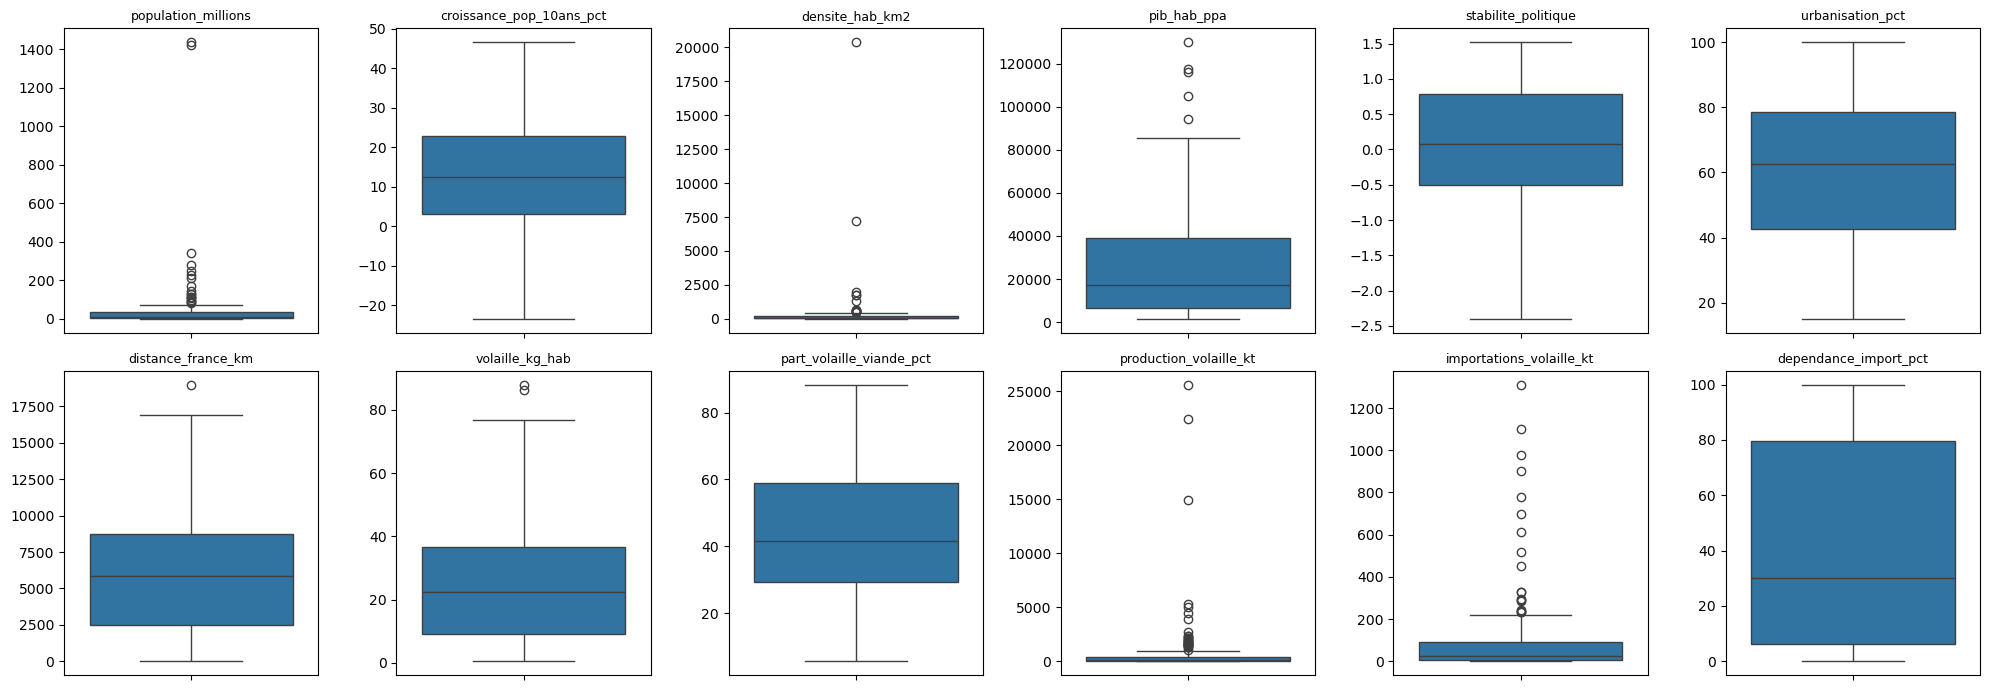

In [21]:
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for ax, variable in zip(axes.flat, VARIABLES):
    sns.boxplot(y=pays[variable], ax=ax)
    ax.set_title(variable, fontsize=9)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [22]:
# qui sont les pays les plus extrêmes ? (exemple sur 4 variables)
print(pays["population_millions"].nlargest(4))
print(pays["production_volaille_kt"].nlargest(4))
print(pays["pib_hab_ppa"].nlargest(4))
print(pays["densite_hab_km2"].nlargest(4))

Zone
Inde                     1438.069596
Chine, continentale      1422.584933
États-Unis d'Amérique     343.477335
Indonésie                 281.190067
Name: population_millions, dtype: float64
Zone
Chine, continentale      25630.0
États-Unis d'Amérique    22443.0
Brésil                   14971.0
Fédération de Russie      5340.0
Name: production_volaille_kt, dtype: float64
Zone
Luxembourg              130048.922273
Irlande                 117659.728594
Qatar                   116159.142564
Chine - RAS de Macao    104815.200031
Name: pib_hab_ppa, dtype: float64
Zone
Chine - RAS de Macao        20384.384384
Chine - RAS de Hong-Kong     7177.238095
Bahreïn                      1971.323750
Maldives                     1765.080537
Name: densite_hab_km2, dtype: float64


Ces valeurs extrêmes ne sont pas des erreurs (comme la Chine et l'Inde qui dépassent le milliard d'habitants, ou les États-Unis et le Brésil qui pèsent des millions de tonnes). Je les garde : les supprimer fausserait la réalité du marché, car ce sont précisément ces contrastes qui permettent de distinguer les pays.

L'écart de **densité est énorme** (à peine 2 habitants au km² dans les pays les plus vides, plus de 20 000 à Macao), ce qui fausserait l'analyse (ACP). J'utilise donc **le logarithme de la densité** pour compresser ces valeurs extrêmes tout en conservant l'ordre des pays. Le logarithme compte en gros les zéros : 100 habitants au km² donnent 2, 1 000 donnent 3.

Dans le notebook 2, même en centrant-réduisant les variables, ces géants garderont une position isolée et pèseront lourdement sur les regroupements.

In [23]:
pays["densite_log10"] = np.log10(pays["densite_hab_km2"])      # 100 hab/km² -> 2 ; 1 000 -> 3
VARIABLES = [v if v != "densite_hab_km2" else "densite_log10" for v in VARIABLES]
pays[["densite_hab_km2", "densite_log10"]].describe().round(1)

,densite_hab_km2,densite_log10
count,170.0,170.0
mean,332.3,1.9
std,1661.2,0.6
min,2.2,0.3
25%,40.5,1.6
50%,86.7,1.9
75%,213.9,2.3
max,20384.4,4.3


## 13. Les liens entre les variables

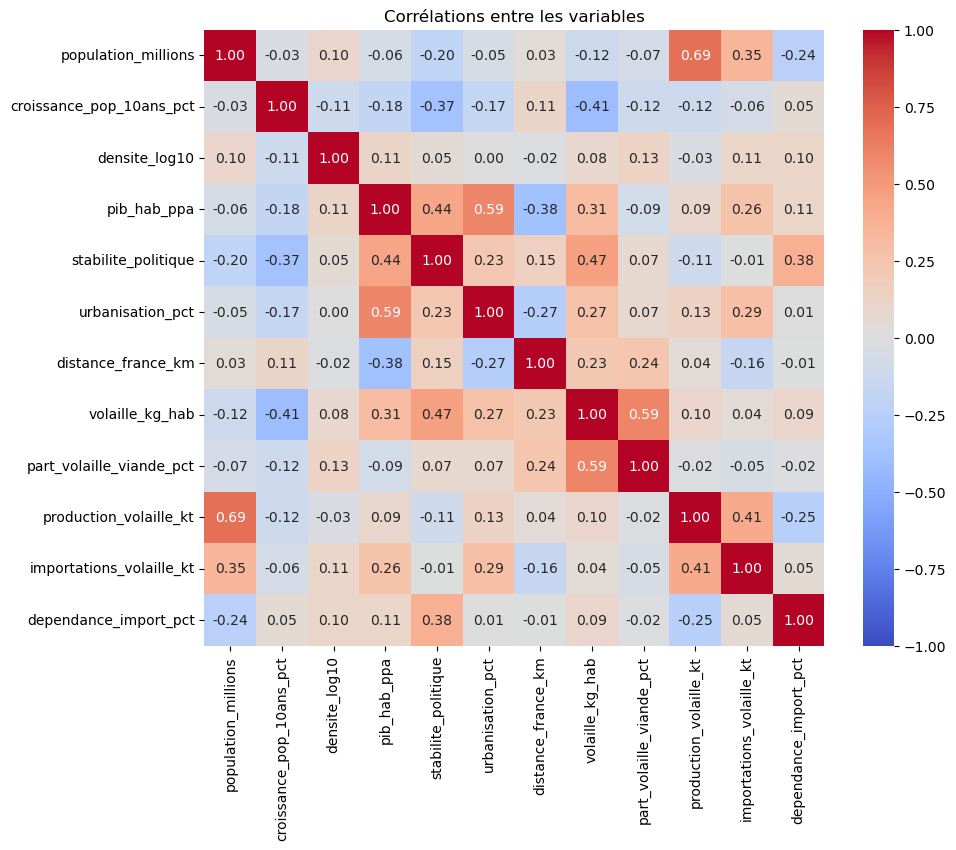

In [24]:
plt.figure(figsize=(10, 8))
sns.heatmap(pays[VARIABLES].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Corrélations entre les variables")
plt.show()

Aucune corrélation ne dépasse 0,7 : chaque variable apporte sa propre information sans doublon. Trois tendances se dégagent :
* Les pays riches sont plus urbains et stables.
* Les grands pays produisent massivement.
* La volaille est la viande principale là où sa consommation par habitant est forte.

L'ACP du notebook 2 devrait retrouver ces trois liens.

## 14. Enregistrer le tableau pour le notebook 2

In [25]:
pays[VARIABLES].to_csv(DOSSIER + "pays_prepares.csv")
print("tableau enregistré :", pays[VARIABLES].shape)

tableau enregistré : (170, 12)


## Synthèse

* Le tableau est prêt : un pays par ligne, 12 variables, sans case vide, couvrant 170 pays et 94,2 % de la population mondiale (6 pays retirés, faute de données).
* J'ai complété la FAO avec quatre indicateurs de la Banque mondiale, choisis avec la grille PESTEL.
* J'ai créé quatre variables : part de la volaille dans la viande, croissance démographique, dépendance aux importations et distance avec la France.
* J'ai gardé les valeurs extrêmes (ce sont de vrais pays) ; seule la densité passe en logarithme.